# 47장 · 필수 검색과 선택 검색의 종료 조건

같은 질문에서도 모든 문서를 확인하는 경로와 필요할 때만 검색하는 경로는 호출 기록이 달라집니다. 각 경로의 종료 사유를 추적합니다.

운영 안내 서비스를 쓰는 사람은 문서에 적힌 절차를 묻습니다. 팀은 문서를 확인하지 않은 답이 나가는 상황을 줄이려고 필수 검색 노드를 골랐습니다. 선택 도구와 비교한 기록에서 두 방식이 언제 갈라지는지 읽습니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요.


## 고정 경로와 선택 경로의 실행 기록

완성 흐름｜질문 Q01 → 검색 노드가 p2를 읽음 → 답변 노드가 p2를 인용 → 화면에 제출 절차와 출처 표시. 46장의 기본 검색 규칙을 유지해 Q03은 여전히 빈 검색으로 끝납니다. 필요한 경우에만 찾아도 되는 팀은 선택 Tool 경로를 별도로 비교할 수 있습니다.


### 셀 01 · 선택 경로의 검색 생략

같은 Q01의 고정 Node 기록과 도구 생략 진단 기록을 읽으세요.

팀이 검색 생략을 허용하면 Q01처럼 문서가 필요한 질문까지 건너뛸 수 있습니다. 반대로 반복 상한을 두면 끝까지 근거를 찾지 못한 질문은 보류해야 합니다. 두 실패 중 이 서비스가 더 신중하게 다뤄야 할 하나를 고르고 그 이유를 기록하세요.


In [1]:
required = {'search_status': 'retrieved',
 'retrieval_calls': 1,
 'generation_calls': 1,
 'decision_calls': 0,
 'stop_reason': 'completed'}
skipped = {'search_status': 'not_requested',
 'retrieval_calls': 0,
 'generation_calls': 0,
 'decision_calls': 1,
 'stop_reason': 'search_skipped'}
print(required['retrieval_calls'], required['stop_reason'])
print(skipped['retrieval_calls'], skipped['stop_reason'])

1 completed
0 search_skipped


필수 경로는 검색 1회 뒤 completed, 생략 진단은 0회 뒤 search_skipped입니다. 검색 생략은 빈 결과를 실제로 받은 경우와 다릅니다.


## 반복 상한과 호출 횟수

도구가 같은 요청을 되풀이하면 추가 검색이 더 좋은 답으로 이어지지 않을 수 있습니다. 제공 사례의 repeat 정책에서는 검색 2회 뒤에 중단하며 답변 생성을 시작하지 않습니다. 팀은 재시도를 허용할 실패와 곧바로 알릴 실패를 구분해 선택하세요.

<!-- lesson-visual visual-loop-limit -->
**검색을 건너뛴 실행과 한도에 닿은 실행**

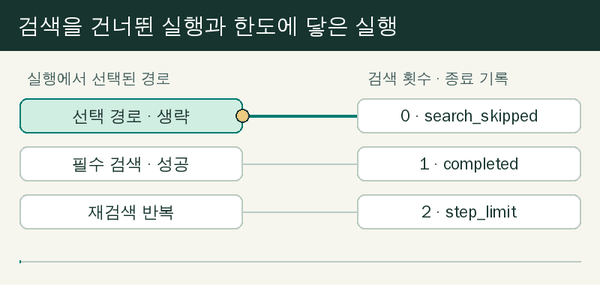

실행 기록에서 검색 횟수를 먼저 보고 마지막 종료 사유를 읽습니다. 두 번 검색한 경우에도 답변이 완성됐다고 볼 수 없습니다.
<!-- /lesson-visual visual-loop-limit -->


### 셀 02 · 반복의 검색·생성 횟수

제공한 실제 그래프 실행 기록에서 어느 시점에서 멈췄는지 읽습니다.


In [2]:
repeated = {'search_status': 'retrieved',
 'retrieval_calls': 2,
 'generation_calls': 0,
 'decision_calls': 3,
 'stop_reason': 'step_limit'}
print(repeated['retrieval_calls'], repeated['generation_calls'], repeated['stop_reason'])

2 0 step_limit


2, 0, step_limit입니다. 동일 질문을 끝없이 처리할 수 없도록 검색 상한을 적용한 결과입니다. 모의 판단 횟수로 외부 모델 비용을 계산하지 않습니다. 팀 그래프도 바꿨다면 Q01을 다시 보내 검색 호출 수와 종료한 노드를 기록하세요. 이 셀의 제공 기록만 읽었다면 진단한 원인까지만 적습니다.


## 돌아보기

다음 화면에 건넬 값은 답과 출처, 또는 종료 사유입니다. 이 프로젝트 예시는 요청마다 새 상태를 쓰므로 화면이 보유한 대화 기록과 체크포인터에 저장된 상태를 혼동하지 마세요.
